In [ ]:
# 07. Whole-Brain Voxelwise Analysis

## Aim

This analysis examined whether the five baseline-defined attention–motivation
phenotypes differed in spatially localized whole-brain activation during
working-memory load (`2-back > 0-back`).

Phenotypes were defined using baseline (`ses-1`) behavioral and self-report
data. Neural outcomes were official subject-level RT-duration contrast maps
from the Penn LEAD analysis pipeline.

The primary analysis included participants with an available official
subject-level contrast map (N = 77).

At each voxel, an OLS model tested the omnibus effect of phenotype while
adjusting for age and sex. The phenotype effect was evaluated using an
omnibus F-test across the five phenotype groups.

Multiple comparisons were controlled across voxels using the
Benjamini–Hochberg false discovery rate (FDR).

This whole-brain analysis was conducted independently of the network-level
results and was not restricted to regions identified in the preceding
network analysis.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt

from scipy.stats import f
from statsmodels.stats.multitest import multipletests
from nilearn import plotting

In [2]:
PROJECT_DIR = Path("/Users/hyuna/OpenNeuro/ds007116")
OPENNEURO_DIR = Path("/Users/hyuna/OpenNeuro/ds007116")

DERIVED_DIR = PROJECT_DIR / "derived"
RESULTS_DIR = PROJECT_DIR / "results" / "summary_tables"
FIGURE_DIR = PROJECT_DIR / "figures"

RTDUR_DIR = (
    OPENNEURO_DIR
    / "derivatives"
    / "level-subject_task-fracback_model-rtdur"
)

CLUSTER_FILE = (
    DERIVED_DIR
    / "gmm_cluster_assignments_k5.csv"
)

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
cluster_df = pd.read_csv(CLUSTER_FILE)

print(cluster_df.shape)
display(cluster_df.head())

(92, 4)


,participant_id,session_id,cluster,prob
0,sub-138950,ses-1,4,0.986002
1,sub-19861,ses-1,1,0.997255
2,sub-20125,ses-1,1,0.983757
3,sub-20139,ses-1,1,0.999997
4,sub-20141,ses-1,1,1.000000


In [4]:
cluster_df["participant_id"] = (
    cluster_df["participant_id"]
    .astype(str)
    .str.replace(r"^sub-", "", regex=True)
    .apply(lambda x: f"sub-{x}")
)

In [5]:
def find_rtdur_effect_maps(participant_id):

    sub = str(participant_id)

    if not sub.startswith("sub-"):
        sub = f"sub-{sub}"

    pattern = (
        f"**/{sub}*task-nback*"
        f"contrast-twoBackMinusZeroBack*"
        f"stat-effect_statmap.nii.gz"
    )

    return sorted(
        RTDUR_DIR.glob(pattern)
    )

In [6]:
records = []

for _, row in cluster_df.iterrows():

    maps = find_rtdur_effect_maps(
        row["participant_id"]
    )

    records.append({
        "participant_id": row["participant_id"],
        "cluster": row["cluster"],
        "n_maps": len(maps),
        "map_path": (
            str(maps[0])
            if len(maps) == 1
            else None
        )
    })

brain_cluster_df = pd.DataFrame(records)

print(
    brain_cluster_df["n_maps"]
    .value_counts()
    .sort_index()
)

assert brain_cluster_df["n_maps"].max() <= 1

brain_cluster_df = (
    brain_cluster_df[
        brain_cluster_df["n_maps"] == 1
    ]
    .copy()
)

print("Brain N =", len(brain_cluster_df))

print(
    brain_cluster_df["cluster"]
    .value_counts()
    .sort_index()
)

n_maps
0    15
1    77
Name: count, dtype: int64
Brain N = 77
cluster
0     6
1    34
2     6
3     6
4    25
Name: count, dtype: int64


In [9]:
covariates = pd.read_csv(
    DERIVED_DIR / "brain_covariates_n77.csv"
)

brain_df = (
    brain_cluster_df
    .merge(
        covariates,
        on="participant_id",
        how="inner",
        validate="one_to_one"
    )
)

print(brain_df.shape)
print(brain_df[["age_c", "sex_M"]].isna().sum())

(77, 8)
age_c    0
sex_M    0
dtype: int64


In [10]:
print(brain_df.shape)

print(
    brain_df["cluster"]
    .value_counts()
    .sort_index()
)

print(
    brain_df[
        ["age_c", "sex_M"]
    ].isna().sum()
)

(77, 8)
cluster
0     6
1    34
2     6
3     6
4    25
Name: count, dtype: int64
age_c    0
sex_M    0
dtype: int64


In [11]:
print(brain_df.columns.tolist())

['participant_id', 'cluster', 'n_maps', 'map_path', 'age', 'sex', 'age_c', 'sex_M']


In [12]:
cluster_dummies = pd.get_dummies(
    brain_df["cluster"],
    prefix="cluster",
    dtype=float
)

cluster_dummies = cluster_dummies[
    [
        "cluster_0",
        "cluster_1",
        "cluster_2",
        "cluster_3",
        "cluster_4"
    ]
]

X = pd.concat(
    [
        cluster_dummies.reset_index(drop=True),
        brain_df[
            ["age_c", "sex_M"]
        ].reset_index(drop=True)
    ],
    axis=1
).astype(float)

print("Design matrix shape:", X.shape)
print("Rank:", np.linalg.matrix_rank(X.to_numpy()))

display(X.head())

Design matrix shape: (77, 7)
Rank: 7


,cluster_0,cluster_1,cluster_2,cluster_3,cluster_4,age_c,sex_M
0,0.0,1.0,0.0,0.0,0.0,2.675325,1.0
1,0.0,1.0,0.0,0.0,0.0,1.675325,0.0
2,0.0,1.0,0.0,0.0,0.0,1.675325,0.0
3,0.0,0.0,0.0,0.0,1.0,0.675325,1.0
4,0.0,1.0,0.0,0.0,0.0,1.675325,0.0


In [13]:
C = np.array([
    [-1,  1,  0,  0,  0, 0, 0],
    [-1,  0,  1,  0,  0, 0, 0],
    [-1,  0,  0,  1,  0, 0, 0],
    [-1,  0,  0,  0,  1, 0, 0],
], dtype=float)

print("Contrast shape:", C.shape)
print("Contrast rank:", np.linalg.matrix_rank(C))

df_num = np.linalg.matrix_rank(C)
df_resid = len(brain_df) - np.linalg.matrix_rank(X)

print("Numerator df:", df_num)
print("Residual df:", df_resid)

Contrast shape: (4, 7)
Contrast rank: 4
Numerator df: 4
Residual df: 70


In [15]:
imgs = [
    nib.load(p)
    for p in brain_df["map_path"]
]

reference_img = imgs[0]

reference_shape = reference_img.shape
reference_affine = reference_img.affine

geometry_ok = []

for img in imgs:

    same_shape = (
        img.shape == reference_shape
    )

    same_affine = np.allclose(
        img.affine,
        reference_affine
    )

    geometry_ok.append(
        same_shape and same_affine
    )

print("All geometry identical:",
      all(geometry_ok))

print("Shape:", reference_shape)

All geometry identical: True
Shape: (91, 109, 91)


In [16]:
data_4d = np.stack(
    [
        img.get_fdata(dtype=np.float32)
        for img in imgs
    ],
    axis=0
)

print(data_4d.shape)

(77, 91, 109, 91)


In [17]:
print(
    "NaN:",
    np.isnan(data_4d).sum()
)

print(
    "Inf:",
    np.isinf(data_4d).sum()
)

NaN: 0
Inf: 0


In [18]:
finite_mask = np.all(
    np.isfinite(data_4d),
    axis=0
)

nonzero_mask = np.any(
    data_4d != 0,
    axis=0
)

analysis_mask = (
    finite_mask &
    nonzero_mask
)

print(
    "Voxels in analysis mask:",
    analysis_mask.sum()
)

Voxels in analysis mask: 325099


In [19]:
coverage = np.mean(
    np.isfinite(data_4d) &
    (data_4d != 0),
    axis=0
)

print(
    "Coverage >= 100%:",
    np.sum(coverage == 1.0)
)

print(
    "Coverage >= 90%:",
    np.sum(coverage >= 0.90)
)

print(
    "Coverage >= 80%:",
    np.sum(coverage >= 0.80)
)

Coverage >= 100%: 174794
Coverage >= 90%: 232542
Coverage >= 80%: 241024


In [20]:
analysis_mask = (
    np.all(np.isfinite(data_4d), axis=0)
    &
    np.all(data_4d != 0, axis=0)
)

print(
    "Final analysis voxels:",
    analysis_mask.sum()
)

analysis_mask_img = nib.Nifti1Image(
    analysis_mask.astype(np.uint8),
    affine=reference_img.affine,
    header=reference_img.header
)

mask_path = (
    DERIVED_DIR /
    "wholebrain_analysis_mask_n77.nii.gz"
)

nib.save(
    analysis_mask_img,
    mask_path
)

print(mask_path)

Final analysis voxels: 174794
/Users/hyuna/OpenNeuro/ds007116/derived/wholebrain_analysis_mask_n77.nii.gz


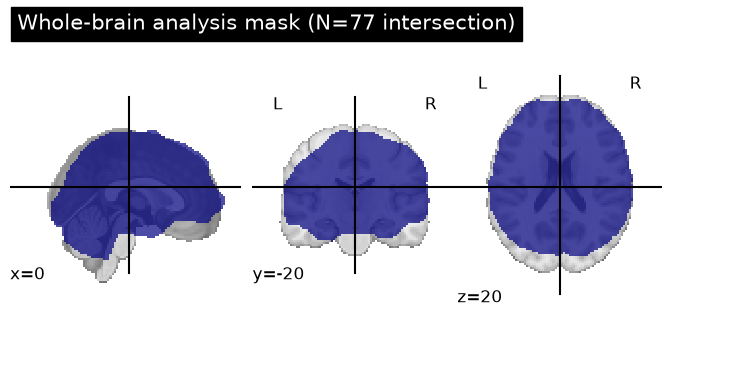

In [21]:
plotting.plot_roi(
    analysis_mask_img,
    title="Whole-brain analysis mask (N=77 intersection)",
    display_mode="ortho",
    cut_coords=(0, -20, 20)
)

plt.show()

In [22]:
plotting.plot_roi(
    analysis_mask_img,
    title="Whole-brain analysis mask",
    display_mode="z",
    cut_coords=8
)

plt.show()

In [23]:
Y = data_4d[:, analysis_mask]

print("Y shape:", Y.shape)
print("Finite:", np.isfinite(Y).all())

Y shape: (77, 174794)
Finite: True


In [24]:
X_np = X.to_numpy(dtype=float)

print("X shape:", X_np.shape)
print("Rank:", np.linalg.matrix_rank(X_np))

n = X_np.shape[0]
p = X_np.shape[1]

df_resid = n - np.linalg.matrix_rank(X_np)

print("N:", n)
print("Parameters:", p)
print("Residual df:", df_resid)

X shape: (77, 7)
Rank: 7
N: 77
Parameters: 7
Residual df: 70


In [25]:
XtX_inv = np.linalg.inv(X_np.T @ X_np)

beta_hat = (
    XtX_inv
    @ X_np.T
    @ Y
)

print("Beta shape:", beta_hat.shape)

Beta shape: (7, 174794)


In [26]:
Y_hat = X_np @ beta_hat

residuals = Y - Y_hat

SSE = np.sum(
    residuals ** 2,
    axis=0
)

sigma2 = SSE / df_resid

print("Residual variance shape:", sigma2.shape)

print(
    "Non-positive residual variances:",
    np.sum(sigma2 <= 0)
)

Residual variance shape: (174794,)
Non-positive residual variances: 0


In [27]:
print(C)

q = np.linalg.matrix_rank(C)

print("Numerator df:", q)

[[-1.  1.  0.  0.  0.  0.  0.]
 [-1.  0.  1.  0.  0.  0.  0.]
 [-1.  0.  0.  1.  0.  0.  0.]
 [-1.  0.  0.  0.  1.  0.  0.]]
Numerator df: 4


In [28]:
CB = C @ beta_hat

middle_inv = np.linalg.inv(
    C @ XtX_inv @ C.T
)

numerator = np.einsum(
    "iv,ij,jv->v",
    CB,
    middle_inv,
    CB
)

F_values = (
    numerator / q
) / sigma2

print("F map values:")
print("Min:", np.nanmin(F_values))
print("Max:", np.nanmax(F_values))
print("Mean:", np.nanmean(F_values))

print(
    "Non-finite F:",
    np.sum(~np.isfinite(F_values))
)

F map values:
Min: 0.0013303334870020088
Max: 13.053684694811654
Mean: 2.023192469453586
Non-finite F: 0


In [29]:
p_values = f.sf(
    F_values,
    q,
    df_resid
)

print("p-value range:")
print(
    np.nanmin(p_values),
    np.nanmax(p_values)
)

print("Raw p < .05:",
      np.sum(p_values < 0.05))

print("Raw p < .01:",
      np.sum(p_values < 0.01))

print("Raw p < .001:",
      np.sum(p_values < 0.001))

p-value range:
5.394571937219205e-08 0.9999963661143607
Raw p < .05: 48764
Raw p < .01: 18546
Raw p < .001: 4292


In [30]:
reject_fdr, p_fdr, _, _ = multipletests(
    p_values,
    alpha=0.05,
    method="fdr_bh"
)

print(
    "Total tested voxels:",
    len(p_values)
)

print(
    "FDR-significant voxels:",
    reject_fdr.sum()
)

if reject_fdr.any():
    print(
        "Largest FDR-adjusted p among significant voxels:",
        p_fdr[reject_fdr].max()
    )

    print(
        "Smallest raw p among significant voxels:",
        p_values[reject_fdr].min()
    )

Total tested voxels: 174794
FDR-significant voxels: 6658
Largest FDR-adjusted p among significant voxels: 0.04999409203969253
Smallest raw p among significant voxels: 5.394571937219205e-08


In [31]:
F_data = np.zeros(
    reference_shape,
    dtype=np.float32
)

F_data[analysis_mask] = F_values

F_img = nib.Nifti1Image(
    F_data,
    affine=reference_img.affine,
    header=reference_img.header
)

F_path = (
    DERIVED_DIR /
    "wholebrain_cluster_omnibus_F_n77.nii.gz"
)

nib.save(
    F_img,
    F_path
)

print(F_path)

/Users/hyuna/OpenNeuro/ds007116/derived/wholebrain_cluster_omnibus_F_n77.nii.gz


In [32]:
F_fdr_data = np.zeros(
    reference_shape,
    dtype=np.float32
)

significant_F = np.where(
    reject_fdr,
    F_values,
    0
)

F_fdr_data[analysis_mask] = significant_F

F_fdr_img = nib.Nifti1Image(
    F_fdr_data,
    affine=reference_img.affine,
    header=reference_img.header
)

F_fdr_path = (
    DERIVED_DIR /
    "wholebrain_cluster_omnibus_F_FDR05_n77.nii.gz"
)

nib.save(
    F_fdr_img,
    F_fdr_path
)

print(F_fdr_path)

/Users/hyuna/OpenNeuro/ds007116/derived/wholebrain_cluster_omnibus_F_FDR05_n77.nii.gz


In [33]:
p_data = np.ones(
    reference_shape,
    dtype=np.float32
)

p_data[analysis_mask] = p_values

p_img = nib.Nifti1Image(
    p_data,
    affine=reference_img.affine,
    header=reference_img.header
)

nib.save(
    p_img,
    DERIVED_DIR /
    "wholebrain_cluster_omnibus_p_uncorrected_n77.nii.gz"
)

In [34]:
p_fdr_data = np.ones(
    reference_shape,
    dtype=np.float32
)

p_fdr_data[analysis_mask] = p_fdr

p_fdr_img = nib.Nifti1Image(
    p_fdr_data,
    affine=reference_img.affine,
    header=reference_img.header
)

nib.save(
    p_fdr_img,
    DERIVED_DIR /
    "wholebrain_cluster_omnibus_p_FDR_n77.nii.gz"
)

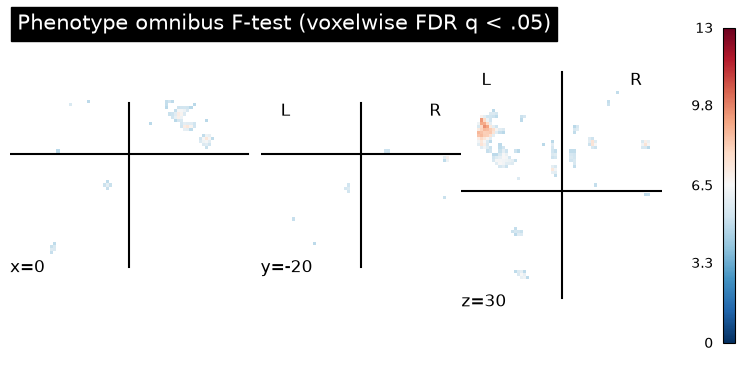

In [35]:
plotting.plot_stat_map(
    F_fdr_img,
    bg_img=None,
    display_mode="ortho",
    cut_coords=(0, -20, 30),
    threshold=1e-12,
    title="Phenotype omnibus F-test (voxelwise FDR q < .05)",
    colorbar=True
)

plt.show()

In [36]:
plotting.plot_stat_map(
    F_fdr_img,
    display_mode="z",
    cut_coords=10,
    threshold=1e-12,
    title="Phenotype omnibus F-test (FDR q < .05)",
    colorbar=True
)

plt.show()

In [37]:
from scipy import ndimage

sig_mask_3d = F_fdr_data > 0

structure = np.ones(
    (3, 3, 3),
    dtype=int
)

labeled_components, n_components = ndimage.label(
    sig_mask_3d,
    structure=structure
)

print("Significant voxels:", sig_mask_3d.sum())
print("Spatial components:", n_components)

Significant voxels: 6658
Spatial components: 168


In [38]:
component_sizes = np.bincount(
    labeled_components.ravel()
)

# 0 = background
component_sizes = component_sizes[1:]

component_table = pd.DataFrame({
    "component": np.arange(
        1,
        n_components + 1
    ),
    "n_voxels": component_sizes
})

component_table = (
    component_table
    .sort_values(
        "n_voxels",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    component_table.head(30)
)

,component,n_voxels
0,3,1520
1,9,795
2,124,559
3,1,342
4,109,291
5,61,278
6,20,229
7,107,223
8,119,165
9,82,158


In [39]:
component_rows = []

for component_id in range(
    1,
    n_components + 1
):

    component_mask = (
        labeled_components
        == component_id
    )

    n_voxels = int(
        component_mask.sum()
    )

    component_F = np.where(
        component_mask,
        F_data,
        -np.inf
    )

    peak_flat = np.argmax(
        component_F
    )

    peak_idx = np.unravel_index(
        peak_flat,
        F_data.shape
    )

    peak_F = float(
        F_data[peak_idx]
    )

    peak_p = float(
        p_data[peak_idx]
    )

    peak_p_fdr = float(
        p_fdr_data[peak_idx]
    )

    # voxel coordinate -> MNI coordinate
    peak_mni = nib.affines.apply_affine(
        reference_img.affine,
        peak_idx
    )

    component_rows.append({
        "component": component_id,
        "n_voxels": n_voxels,
        "peak_F": peak_F,
        "peak_p": peak_p,
        "peak_p_fdr": peak_p_fdr,
        "x": peak_mni[0],
        "y": peak_mni[1],
        "z": peak_mni[2]
    })

component_peaks = pd.DataFrame(
    component_rows
)

component_peaks = (
    component_peaks
    .sort_values(
        "n_voxels",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    component_peaks.head(30).round(5)
)

,component,n_voxels,peak_F,peak_p,peak_p_fdr,x,y,z
0,3,1520,13.05368,0.00000,0.00943,-52.0,16.0,34.0
1,9,795,10.63486,0.00000,0.01262,-26.0,-60.0,46.0
2,124,559,9.83833,0.00000,0.01262,32.0,-48.0,44.0
3,1,342,10.34437,0.00000,0.01262,-54.0,-56.0,-16.0
4,109,291,8.25949,0.00002,0.01518,24.0,-4.0,54.0
5,61,278,10.50327,0.00000,0.01262,-4.0,18.0,50.0
6,20,229,8.96123,0.00001,0.01406,-28.0,22.0,4.0
7,107,223,6.70124,0.00013,0.02298,32.0,-54.0,-36.0
8,119,165,9.02694,0.00001,0.01406,32.0,24.0,2.0
9,82,158,7.82678,0.00003,0.01675,8.0,-76.0,-26.0


In [40]:
from nilearn import datasets
from nilearn.image import resample_to_img

atlas = datasets.fetch_atlas_schaefer_2018(
    n_rois=100,
    yeo_networks=7,
    resolution_mm=2
)

atlas_img = nib.load(
    atlas.maps
)

atlas_resampled = resample_to_img(
    atlas_img,
    reference_img,
    interpolation="nearest",
    force_resample=True,
    copy_header=True
)

atlas_data = (
    atlas_resampled
    .get_fdata()
    .astype(int)
)

print(
    "Atlas labels:",
    len(np.unique(atlas_data))
)

[fetch_atlas_schaefer_2018] Dataset directory found: /Users/hyuna/nilearn_data/schaefer_2018
Atlas labels: 101


In [41]:
labels = [
    x.decode() if isinstance(x, bytes) else str(x)
    for x in atlas.labels
]

labels[:10]

['Background',
 '7Networks_LH_Vis_1',
 '7Networks_LH_Vis_2',
 '7Networks_LH_Vis_3',
 '7Networks_LH_Vis_4',
 '7Networks_LH_Vis_5',
 '7Networks_LH_Vis_6',
 '7Networks_LH_Vis_7',
 '7Networks_LH_Vis_8',
 '7Networks_LH_Vis_9']

In [42]:
def get_yeo_network(label):

    if "Vis" in label:
        return "Vis"

    elif "SomMot" in label:
        return "SomMot"

    elif "DorsAttn" in label:
        return "DorsAttn"

    elif "SalVentAttn" in label:
        return "SalVentAttn"

    elif "Limbic" in label:
        return "Limbic"

    elif "Cont" in label:
        return "Cont"

    elif "Default" in label:
        return "Default"

    else:
        return "Unknown"

In [43]:
parcel_network = {}

for parcel_id in range(1, 101):

    label = labels[parcel_id]

    parcel_network[parcel_id] = (
        get_yeo_network(label)
    )

In [44]:
network_overlap_rows = []

for network in [
    "Vis",
    "SomMot",
    "DorsAttn",
    "SalVentAttn",
    "Limbic",
    "Cont",
    "Default"
]:

    parcel_ids = [
        parcel_id
        for parcel_id, net
        in parcel_network.items()
        if net == network
    ]

    network_mask = np.isin(
        atlas_data,
        parcel_ids
    )

    n_network_voxels = np.sum(
        analysis_mask &
        network_mask
    )

    n_sig_voxels = np.sum(
        sig_mask_3d &
        network_mask
    )

    network_overlap_rows.append({
        "network": network,
        "analysis_voxels": n_network_voxels,
        "significant_voxels": n_sig_voxels,
        "percent_significant": (
            100 * n_sig_voxels /
            n_network_voxels
            if n_network_voxels > 0
            else np.nan
        )
    })

network_overlap = pd.DataFrame(
    network_overlap_rows
)

display(
    network_overlap
    .sort_values(
        "percent_significant",
        ascending=False
    )
    .round(2)
)

,network,analysis_voxels,significant_voxels,percent_significant
2,DorsAttn,12979,1972,15.19
5,Cont,11918,1554,13.04
3,SalVentAttn,12577,666,5.30
4,Limbic,4123,165,4.00
6,Default,25646,437,1.70
0,Vis,14496,97,0.67
1,SomMot,12220,10,0.08


In [48]:
from nilearn import datasets
from nilearn.image import resample_to_img

# --------------------------------------------------
# Harvard-Oxford cortical atlas
# --------------------------------------------------

ho_cort = datasets.fetch_atlas_harvard_oxford(
    "cort-maxprob-thr25-2mm"
)

# 현재 Nilearn에서는 .maps 자체가 Nifti1Image
ho_cort_img = ho_cort.maps

ho_cort_resampled = resample_to_img(
    ho_cort_img,
    reference_img,
    interpolation="nearest",
    force_resample=True,
    copy_header=True
)

ho_cort_data = (
    ho_cort_resampled
    .get_fdata()
    .astype(int)
)


# --------------------------------------------------
# Harvard-Oxford subcortical atlas
# --------------------------------------------------

ho_sub = datasets.fetch_atlas_harvard_oxford(
    "sub-maxprob-thr25-2mm"
)

ho_sub_img = ho_sub.maps

ho_sub_resampled = resample_to_img(
    ho_sub_img,
    reference_img,
    interpolation="nearest",
    force_resample=True,
    copy_header=True
)

ho_sub_data = (
    ho_sub_resampled
    .get_fdata()
    .astype(int)
)


# --------------------------------------------------
# QC
# --------------------------------------------------

print("Reference shape:", reference_img.shape)
print("Cortical atlas shape:", ho_cort_resampled.shape)
print("Subcortical atlas shape:", ho_sub_resampled.shape)

print()
print("Cortical labels:", len(ho_cort.labels))
print("Subcortical labels:", len(ho_sub.labels))

print()
print(
    "Cortical atlas IDs:",
    np.unique(ho_cort_data)[:20],
    "... max =", ho_cort_data.max()
)

print(
    "Subcortical atlas IDs:",
    np.unique(ho_sub_data)[:20],
    "... max =", ho_sub_data.max()
)

[fetch_atlas_harvard_oxford] Dataset directory found: /Users/hyuna/nilearn_data/fsl
[fetch_atlas_harvard_oxford] Dataset directory found: /Users/hyuna/nilearn_data/fsl
Reference shape: (91, 109, 91)
Cortical atlas shape: (91, 109, 91)
Subcortical atlas shape: (91, 109, 91)

Cortical labels: 49
Subcortical labels: 22

Cortical atlas IDs: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19] ... max = 48
Subcortical atlas IDs: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19] ... max = 21


In [49]:
def atlas_label_at_voxel(atlas_data, labels, voxel_idx):
    label_id = int(atlas_data[voxel_idx])

    if label_id == 0:
        return "Outside atlas"

    if label_id < len(labels):
        return str(labels[label_id])

    return "Unknown"

In [50]:
anatomical_rows = []

for component_id in range(1, n_components + 1):

    component_mask = (
        labeled_components == component_id
    )

    component_F = np.where(
        component_mask,
        F_data,
        -np.inf
    )

    peak_flat = np.argmax(component_F)

    peak_idx = np.unravel_index(
        peak_flat,
        F_data.shape
    )

    peak_mni = nib.affines.apply_affine(
        reference_img.affine,
        peak_idx
    )

    cortical_label = atlas_label_at_voxel(
        ho_cort_data,
        ho_cort.labels,
        peak_idx
    )

    subcortical_label = atlas_label_at_voxel(
        ho_sub_data,
        ho_sub.labels,
        peak_idx
    )

    anatomical_rows.append({
        "component": component_id,
        "n_voxels": int(component_mask.sum()),
        "peak_F": float(F_data[peak_idx]),
        "peak_p_fdr": float(p_fdr_data[peak_idx]),
        "x": peak_mni[0],
        "y": peak_mni[1],
        "z": peak_mni[2],
        "cortical_label": cortical_label,
        "subcortical_label": subcortical_label
    })

anatomical_components = pd.DataFrame(
    anatomical_rows
).sort_values(
    "n_voxels",
    ascending=False
).reset_index(drop=True)

display(
    anatomical_components.head(30)
)

,component,n_voxels,peak_F,peak_p_fdr,x,y,z,cortical_label,subcortical_label
0,3,1520,13.053684,0.009429,-52.0,16.0,34.0,Middle Frontal Gyrus,Left Cerebral Cortex
1,9,795,10.634859,0.012625,-26.0,-60.0,46.0,"Lateral Occipital Cortex, superior division",Left Cerebral Cortex
2,124,559,9.838333,0.012625,32.0,-48.0,44.0,Superior Parietal Lobule,Right Cerebral Cortex
3,1,342,10.344369,0.012625,-54.0,-56.0,-16.0,"Inferior Temporal Gyrus, temporooccipital part",Left Cerebral Cortex
4,109,291,8.259494,0.015183,24.0,-4.0,54.0,Outside atlas,Right Cerebral Cortex
5,61,278,10.503270,0.012625,-4.0,18.0,50.0,Paracingulate Gyrus,Left Cerebral Cortex
6,20,229,8.961227,0.014060,-28.0,22.0,4.0,Outside atlas,Left Cerebral White Matter
7,107,223,6.701236,0.022978,32.0,-54.0,-36.0,Outside atlas,Outside atlas
8,119,165,9.026941,0.014060,32.0,24.0,2.0,Insular Cortex,Right Cerebral Cortex
9,82,158,7.826783,0.016747,8.0,-76.0,-26.0,Outside atlas,Outside atlas


In [51]:
component_overlap_rows = []

for component_id in range(1, n_components + 1):

    component_mask = (
        labeled_components == component_id
    )

    atlas_values = ho_cort_data[
        component_mask
    ]

    atlas_values = atlas_values[
        atlas_values > 0
    ]

    if len(atlas_values) == 0:
        continue

    ids, counts = np.unique(
        atlas_values,
        return_counts=True
    )

    total_labeled = counts.sum()

    for label_id, count in zip(ids, counts):

        component_overlap_rows.append({
            "component": component_id,
            "atlas_label": str(
                ho_cort.labels[label_id]
            ),
            "n_voxels": int(count),
            "percent_of_labeled_component": (
                100 * count / total_labeled
            )
        })

component_anatomical_overlap = pd.DataFrame(
    component_overlap_rows
)

component_anatomical_overlap = (
    component_anatomical_overlap
    .sort_values(
        ["component", "n_voxels"],
        ascending=[True, False]
    )
)

display(
    component_anatomical_overlap
    .groupby("component")
    .head(5)
)

,component,atlas_label,n_voxels,percent_of_labeled_component
3,1,"Inferior Temporal Gyrus, temporooccipital part",217,67.601246
1,1,"Middle Temporal Gyrus, temporooccipital part",88,27.414330
5,1,Temporal Occipital Fusiform Cortex,8,2.492212
0,1,"Middle Temporal Gyrus, posterior division",4,1.246106
6,1,Occipital Fusiform Gyrus,2,0.623053
...,...,...,...,...
139,166,"Middle Temporal Gyrus, temporooccipital part",8,61.538462
140,166,"Inferior Temporal Gyrus, temporooccipital part",5,38.461538
142,167,Planum Temporale,8,88.888889
141,167,"Supramarginal Gyrus, posterior division",1,11.111111


In [55]:
# --------------------------------------------------
# Spatial component sizes
# --------------------------------------------------

component_ids, component_counts = np.unique(
    labeled_components[labeled_components > 0],
    return_counts=True
)

component_size_df = pd.DataFrame({
    "component": component_ids.astype(int),
    "n_voxels": component_counts.astype(int)
})

component_size_df = (
    component_size_df
    .sort_values("n_voxels", ascending=False)
    .reset_index(drop=True)
)

print("Total spatial components:", len(component_size_df))
print("Total significant voxels:", component_size_df["n_voxels"].sum())

display(component_size_df.head(20))

Total spatial components: 168
Total significant voxels: 6658


,component,n_voxels
0,3,1520
1,9,795
2,124,559
3,1,342
4,109,291
5,61,278
6,20,229
7,107,223
8,119,165
9,82,158


In [56]:
top_components = (
    component_size_df
    .head(10)["component"]
    .tolist()
)

print("Top 10 components:", top_components)

display(
    component_size_df.head(10)
)

Top 10 components: [3, 9, 124, 1, 109, 61, 20, 107, 119, 82]


,component,n_voxels
0,3,1520
1,9,795
2,124,559
3,1,342
4,109,291
5,61,278
6,20,229
7,107,223
8,119,165
9,82,158


In [57]:
# --------------------------------------------------
# Participant-level mean contrast
# within each of the 10 largest components
# --------------------------------------------------

component_subject_df = brain_df[
    [
        "participant_id",
        "cluster",
        "age_c",
        "sex_M"
    ]
].copy().reset_index(drop=True)

for component_id in top_components:

    component_mask = (
        labeled_components == component_id
    )

    component_values = data_4d[
        :,
        component_mask
    ].mean(axis=1)

    component_subject_df[
        f"component_{component_id}"
    ] = component_values


print(
    "Shape:",
    component_subject_df.shape
)

print(
    "Participants:",
    component_subject_df[
        "participant_id"
    ].nunique()
)

print(
    "Missing component values:",
    component_subject_df.isna().sum().sum()
)

display(
    component_subject_df.head()
)

Shape: (77, 14)
Participants: 77
Missing component values: 0


,participant_id,cluster,age_c,sex_M,component_3,component_9,component_124,component_1,component_109,component_61,component_20,component_107,component_119,component_82
0,sub-19861,1,2.675325,1,0.414493,0.161163,0.258871,0.041349,0.335600,0.529770,0.296733,0.199871,0.268453,0.296971
1,sub-20139,1,1.675325,0,0.184909,0.151500,0.283922,-0.194182,0.342075,0.546363,0.158679,0.051042,0.323545,-0.048263
2,sub-20141,1,1.675325,0,0.204006,0.119206,0.168126,-0.149312,0.484950,0.330887,0.148496,0.095476,0.164497,0.018515
3,sub-20188,4,0.675325,1,0.371721,0.420144,0.352196,0.197702,0.473497,0.568052,0.464051,0.446384,0.744860,0.470303
4,sub-20214,1,1.675325,0,0.073713,-0.008393,-0.040019,-0.178300,-0.027424,0.036927,0.117707,-0.010979,0.152590,-0.103072


In [58]:
assert len(component_subject_df) == data_4d.shape[0]
assert len(component_subject_df) == 77

In [59]:
component_cols = [
    f"component_{c}"
    for c in top_components
]

raw_component_means = (
    component_subject_df
    .groupby("cluster")[component_cols]
    .mean()
    .T
)

raw_component_means.columns = [
    f"C{c}"
    for c in raw_component_means.columns
]

# component size 추가
size_lookup = (
    component_size_df
    .set_index("component")["n_voxels"]
    .to_dict()
)

raw_component_means.insert(
    0,
    "n_voxels",
    [
        size_lookup[c]
        for c in top_components
    ]
)

display(
    raw_component_means.round(4)
)

,n_voxels,C0,C1,C2,C3,C4
component_3,1520,-0.2717,0.2440,-0.0703,-0.1587,0.2367
component_9,795,-0.1926,0.2069,-0.0338,-0.0836,0.1864
component_124,559,-0.1391,0.2651,-0.0206,-0.0665,0.2593
component_1,342,-0.3768,0.0998,-0.2807,-0.2909,-0.0180
component_109,291,-0.1761,0.2624,0.0559,-0.0578,0.2915
component_61,278,-0.2010,0.3420,0.0916,-0.0958,0.3780
component_20,229,-0.1276,0.2197,-0.0364,-0.1293,0.2456
component_107,223,-0.2128,0.1706,-0.0299,-0.1787,0.1474
component_119,165,-0.0439,0.2806,-0.0309,-0.1591,0.2975
component_82,158,-0.3994,0.2152,-0.1116,-0.2174,0.1718


In [61]:
# cluster를 categorical variable로 명시
component_subject_df["cluster"] = pd.Categorical(
    component_subject_df["cluster"],
    categories=[0, 1, 2, 3, 4]
)

print(component_subject_df["cluster"].dtype)
print(component_subject_df["cluster"].value_counts().sort_index())

category
cluster
0     6
1    34
2     6
3     6
4    25
Name: count, dtype: int64


In [62]:
import statsmodels.formula.api as smf

adjusted_rows = []
component_models = {}

for component_id in top_components:

    outcome = f"component_{component_id}"

    # cluster가 이미 categorical dtype이므로 C() 불필요
    model = smf.ols(
        formula=f"{outcome} ~ cluster + age_c + sex_M",
        data=component_subject_df
    ).fit()

    component_models[component_id] = model

    # 각 phenotype에 대한 standardized adjusted mean
    for cluster_id in [0, 1, 2, 3, 4]:

        pred_df = component_subject_df[
            ["cluster", "age_c", "sex_M"]
        ].copy()

        # categorical dtype 유지하면서 cluster만 변경
        pred_df["cluster"] = pd.Categorical(
            [cluster_id] * len(pred_df),
            categories=[0, 1, 2, 3, 4]
        )

        predictions = model.predict(pred_df)

        adjusted_rows.append({
            "component": int(component_id),
            "cluster": cluster_id,
            "adjusted_mean": float(predictions.mean())
        })

component_adjusted_means = pd.DataFrame(adjusted_rows)

print("Shape:", component_adjusted_means.shape)
print("Missing:", component_adjusted_means.isna().sum())
display(component_adjusted_means.head(15))

Shape: (50, 3)
Missing: component        0
cluster          0
adjusted_mean    0
dtype: int64


,component,cluster,adjusted_mean
0,3,0,-0.291994
1,3,1,0.242857
2,3,2,-0.050381
3,3,3,-0.115346
4,3,4,0.227971
5,9,0,-0.210563
6,9,1,0.202383
7,9,2,-0.015793
8,9,3,-0.044639
9,9,4,0.183114


In [63]:
component_profile_table = (
    component_adjusted_means
    .pivot(
        index="component",
        columns="cluster",
        values="adjusted_mean"
    )
    .reset_index()
)

component_profile_table = component_profile_table.rename(
    columns={
        0: "C0",
        1: "C1",
        2: "C2",
        3: "C3",
        4: "C4"
    }
)

component_profile_table = (
    component_profile_table
    .merge(
        component_size_df[
            ["component", "n_voxels"]
        ],
        on="component",
        how="left"
    )
    .sort_values(
        "n_voxels",
        ascending=False
    )
    .reset_index(drop=True)
)

display(component_profile_table.round(4))

,component,C0,C1,C2,C3,C4,n_voxels
0,3,-0.2920,0.2429,-0.0504,-0.1153,0.2280,1520
1,9,-0.2106,0.2024,-0.0158,-0.0446,0.1831,795
2,124,-0.1582,0.2615,-0.0017,-0.0253,0.2544,559
3,1,-0.3888,0.1004,-0.2691,-0.2656,-0.0247,342
4,109,-0.1996,0.2607,0.0789,-0.0077,0.2819,291
5,61,-0.2393,0.3408,0.1290,-0.0143,0.3603,278
6,20,-0.1424,0.2203,-0.0221,-0.0979,0.2374,229
7,107,-0.2294,0.1700,-0.0136,-0.1432,0.1398,223
8,119,-0.0565,0.2793,-0.0185,-0.1322,0.2929,165
9,82,-0.4194,0.2115,-0.0918,-0.1744,0.1666,158


In [64]:
top_component_summary = (
    component_profile_table
    .merge(
        anatomical_components[
            [
                "component",
                "peak_F",
                "peak_p_fdr",
                "x",
                "y",
                "z",
                "cortical_label",
                "subcortical_label"
            ]
        ],
        on="component",
        how="left"
    )
)

display(
    top_component_summary.round(4)
)

,component,C0,C1,C2,C3,C4,n_voxels,peak_F,peak_p_fdr,x,y,z,cortical_label,subcortical_label
0,3,-0.2920,0.2429,-0.0504,-0.1153,0.2280,1520,13.0537,0.0094,-52.0,16.0,34.0,Middle Frontal Gyrus,Left Cerebral Cortex
1,9,-0.2106,0.2024,-0.0158,-0.0446,0.1831,795,10.6349,0.0126,-26.0,-60.0,46.0,"Lateral Occipital Cortex, superior division",Left Cerebral Cortex
2,124,-0.1582,0.2615,-0.0017,-0.0253,0.2544,559,9.8383,0.0126,32.0,-48.0,44.0,Superior Parietal Lobule,Right Cerebral Cortex
3,1,-0.3888,0.1004,-0.2691,-0.2656,-0.0247,342,10.3444,0.0126,-54.0,-56.0,-16.0,"Inferior Temporal Gyrus, temporooccipital part",Left Cerebral Cortex
4,109,-0.1996,0.2607,0.0789,-0.0077,0.2819,291,8.2595,0.0152,24.0,-4.0,54.0,Outside atlas,Right Cerebral Cortex
5,61,-0.2393,0.3408,0.1290,-0.0143,0.3603,278,10.5033,0.0126,-4.0,18.0,50.0,Paracingulate Gyrus,Left Cerebral Cortex
6,20,-0.1424,0.2203,-0.0221,-0.0979,0.2374,229,8.9612,0.0141,-28.0,22.0,4.0,Outside atlas,Left Cerebral White Matter
7,107,-0.2294,0.1700,-0.0136,-0.1432,0.1398,223,6.7012,0.0230,32.0,-54.0,-36.0,Outside atlas,Outside atlas
8,119,-0.0565,0.2793,-0.0185,-0.1322,0.2929,165,9.0269,0.0141,32.0,24.0,2.0,Insular Cortex,Right Cerebral Cortex
9,82,-0.4194,0.2115,-0.0918,-0.1744,0.1666,158,7.8268,0.0167,8.0,-76.0,-26.0,Outside atlas,Outside atlas


In [65]:
print("n_components =", n_components)

print(
    "Total labeled significant voxels =",
    np.sum(labeled_components > 0)
)

print(
    "Unique component IDs =",
    len(np.unique(labeled_components[labeled_components > 0]))
)

display(component_size_df.head(20))

n_components = 168
Total labeled significant voxels = 6658
Unique component IDs = 168


,component,n_voxels
0,3,1520
1,9,795
2,124,559
3,1,342
4,109,291
5,61,278
6,20,229
7,107,223
8,119,165
9,82,158


In [66]:
# ============================================================
# 36. Anatomical overlap of top 10 spatial components
#     Harvard-Oxford cortical + subcortical
# ============================================================

anatomical_overlap_rows = []

for component_id in top_components:

    component_mask = (labeled_components == component_id)
    total_component_voxels = int(component_mask.sum())

    # --------------------------------------------------------
    # Cortical atlas overlap
    # --------------------------------------------------------
    cort_values = ho_cort_data[component_mask]

    cort_ids, cort_counts = np.unique(
        cort_values[cort_values > 0],
        return_counts=True
    )

    for label_id, count in zip(cort_ids, cort_counts):

        anatomical_overlap_rows.append({
            "component": int(component_id),
            "atlas": "Harvard-Oxford cortical",
            "region": str(ho_cort.labels[int(label_id)]),
            "n_voxels": int(count),
            "percent_component": (
                100 * count / total_component_voxels
            )
        })

    # --------------------------------------------------------
    # Subcortical atlas overlap
    # --------------------------------------------------------
    sub_values = ho_sub_data[component_mask]

    sub_ids, sub_counts = np.unique(
        sub_values[sub_values > 0],
        return_counts=True
    )

    for label_id, count in zip(sub_ids, sub_counts):

        anatomical_overlap_rows.append({
            "component": int(component_id),
            "atlas": "Harvard-Oxford subcortical",
            "region": str(ho_sub.labels[int(label_id)]),
            "n_voxels": int(count),
            "percent_component": (
                100 * count / total_component_voxels
            )
        })


anatomical_overlap_df = pd.DataFrame(
    anatomical_overlap_rows
)

anatomical_overlap_df = (
    anatomical_overlap_df
    .sort_values(
        ["component", "n_voxels"],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)

print("Rows:", len(anatomical_overlap_df))

display(
    anatomical_overlap_df.head(30)
)

Rows: 55


,component,atlas,region,n_voxels,percent_component
0,1,Harvard-Oxford subcortical,Left Cerebral Cortex,313,91.520468
1,1,Harvard-Oxford cortical,"Inferior Temporal Gyrus, temporooccipital part",217,63.450292
2,1,Harvard-Oxford cortical,"Middle Temporal Gyrus, temporooccipital part",88,25.730994
3,1,Harvard-Oxford subcortical,Left Cerebral White Matter,29,8.479532
4,1,Harvard-Oxford cortical,Temporal Occipital Fusiform Cortex,8,2.339181
5,1,Harvard-Oxford cortical,"Middle Temporal Gyrus, posterior division",4,1.169591
6,1,Harvard-Oxford cortical,Occipital Fusiform Gyrus,2,0.584795
7,1,Harvard-Oxford cortical,"Inferior Temporal Gyrus, posterior division",1,0.292398
8,1,Harvard-Oxford cortical,"Lateral Occipital Cortex, inferior division",1,0.292398
9,3,Harvard-Oxford subcortical,Left Cerebral Cortex,1163,76.513158


In [67]:
top_anatomical_regions = (
    anatomical_overlap_df
    .sort_values(
        ["component", "n_voxels"],
        ascending=[True, False]
    )
    .groupby(
        "component",
        group_keys=False
    )
    .head(5)
)

# component 크기 붙이기
top_anatomical_regions = (
    top_anatomical_regions
    .merge(
        component_size_df[
            ["component", "n_voxels"]
        ].rename(
            columns={
                "n_voxels": "component_size"
            }
        ),
        on="component",
        how="left"
    )
)

# 큰 component 순으로 정렬
top_anatomical_regions = (
    top_anatomical_regions
    .sort_values(
        ["component_size", "n_voxels"],
        ascending=[False, False]
    )
    .reset_index(drop=True)
)

display(
    top_anatomical_regions.round(2)
)

,component,atlas,region,n_voxels,percent_component,component_size
0,3,Harvard-Oxford subcortical,Left Cerebral Cortex,1163,76.51,1520
1,3,Harvard-Oxford cortical,Frontal Pole,425,27.96,1520
2,3,Harvard-Oxford cortical,Middle Frontal Gyrus,360,23.68,1520
3,3,Harvard-Oxford subcortical,Left Cerebral White Matter,357,23.49,1520
4,3,Harvard-Oxford cortical,Precentral Gyrus,195,12.83,1520
5,9,Harvard-Oxford subcortical,Left Cerebral Cortex,462,58.11,795
6,9,Harvard-Oxford subcortical,Left Cerebral White Matter,333,41.89,795
7,9,Harvard-Oxford cortical,"Lateral Occipital Cortex, superior division",241,30.31,795
8,9,Harvard-Oxford cortical,Superior Parietal Lobule,148,18.62,795
9,9,Harvard-Oxford cortical,Postcentral Gyrus,34,4.28,795


In [68]:
coverage_rows = []

for component_id in top_components:

    component_mask = (
        labeled_components == component_id
    )

    total = int(
        component_mask.sum()
    )

    cort = ho_cort_data[
        component_mask
    ]

    sub = ho_sub_data[
        component_mask
    ]

    covered = (
        (cort > 0) |
        (sub > 0)
    )

    n_covered = int(
        covered.sum()
    )

    n_uncovered = int(
        (~covered).sum()
    )

    coverage_rows.append({
        "component": int(component_id),
        "n_voxels": total,
        "HO_covered": n_covered,
        "HO_uncovered": n_uncovered,
        "percent_uncovered": (
            100 * n_uncovered / total
        )
    })


ho_coverage_df = pd.DataFrame(
    coverage_rows
)

ho_coverage_df = (
    ho_coverage_df
    .sort_values(
        "n_voxels",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    ho_coverage_df.round(2)
)

,component,n_voxels,HO_covered,HO_uncovered,percent_uncovered
0,3,1520,1520,0,0.0
1,9,795,795,0,0.0
2,124,559,559,0,0.0
3,1,342,342,0,0.0
4,109,291,291,0,0.0
5,61,278,278,0,0.0
6,20,229,229,0,0.0
7,107,223,0,223,100.0
8,119,165,165,0,0.0
9,82,158,0,158,100.0


In [69]:
from nilearn import datasets
from nilearn.image import resample_to_img

# --------------------------------------------------
# AAL atlas
# --------------------------------------------------

aal = datasets.fetch_atlas_aal()

print(type(aal.maps))
print("Number of labels:", len(aal.labels))
print("First labels:", aal.labels[:10])
print("First indices:", aal.indices[:10])

[fetch_atlas_aal] Dataset directory found: /Users/hyuna/nilearn_data/aal_3v2
<class 'str'>
Number of labels: 167
First labels: ['Background', 'Precentral_L', 'Precentral_R', 'Frontal_Sup_2_L', 'Frontal_Sup_2_R', 'Frontal_Mid_2_L', 'Frontal_Mid_2_R', 'Frontal_Inf_Oper_L', 'Frontal_Inf_Oper_R', 'Frontal_Inf_Tri_L']
First indices: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']


In [70]:
if isinstance(aal.maps, (str, Path)):
    aal_img = nib.load(aal.maps)
else:
    aal_img = aal.maps

aal_resampled = resample_to_img(
    aal_img,
    reference_img,
    interpolation="nearest",
    force_resample=True,
    copy_header=True
)

aal_data = aal_resampled.get_fdata().astype(int)

print("Reference shape:", reference_img.shape)
print("AAL shape:", aal_resampled.shape)
print("AAL unique labels:", len(np.unique(aal_data)))

Reference shape: (91, 109, 91)
AAL shape: (91, 109, 91)
AAL unique labels: 167


In [71]:
aal_label_map = {
    int(index): str(label)
    for index, label
    in zip(aal.indices, aal.labels)
}

print(
    list(aal_label_map.items())[:10]
)

[(0, 'Background'), (1, 'Precentral_L'), (2, 'Precentral_R'), (3, 'Frontal_Sup_2_L'), (4, 'Frontal_Sup_2_R'), (5, 'Frontal_Mid_2_L'), (6, 'Frontal_Mid_2_R'), (7, 'Frontal_Inf_Oper_L'), (8, 'Frontal_Inf_Oper_R'), (9, 'Frontal_Inf_Tri_L')]


In [72]:
components_outside_ho = [107, 82]

aal_overlap_rows = []

for component_id in components_outside_ho:

    component_mask = (
        labeled_components == component_id
    )

    total = int(component_mask.sum())

    values = aal_data[
        component_mask
    ]

    ids, counts = np.unique(
        values[values > 0],
        return_counts=True
    )

    for label_id, count in zip(ids, counts):

        aal_overlap_rows.append({
            "component": component_id,
            "region": aal_label_map.get(
                int(label_id),
                f"Unknown_{label_id}"
            ),
            "n_voxels": int(count),
            "percent_component": (
                100 * count / total
            )
        })


aal_overlap_df = pd.DataFrame(
    aal_overlap_rows
)

aal_overlap_df = (
    aal_overlap_df
    .sort_values(
        ["component", "n_voxels"],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)

display(
    aal_overlap_df.round(2)
)

,component,region,n_voxels,percent_component
0,82,Cerebellum_6_R,67,42.41
1,82,Cerebellum_Crus1_R,49,31.01
2,82,Cerebellum_Crus2_R,23,14.56
3,82,Vermis_7,15,9.49
4,82,Vermis_6,3,1.90
5,107,Cerebellum_Crus1_R,107,47.98
6,107,Cerebellum_6_R,91,40.81


In [73]:
for component_id in components_outside_ho:

    mask = (
        labeled_components == component_id
    )

    total = int(mask.sum())

    covered = int(
        np.sum(aal_data[mask] > 0)
    )

    print(
        f"Component {component_id}: "
        f"{covered}/{total} voxels "
        f"({100 * covered / total:.1f}%) covered by AAL"
    )

Component 107: 198/223 voxels (88.8%) covered by AAL
Component 82: 157/158 voxels (99.4%) covered by AAL


In [74]:
report_labels = {
    3: "Left frontal cortex",
    9: "Left lateral occipital / superior parietal cortex",
    124: "Right superior parietal / supramarginal cortex",
    1: "Left temporo-occipital cortex",
    109: "Right superior / middle frontal cortex",
    61: "Medial frontal / paracingulate cortex",
    20: "Left insular / frontal opercular cortex",
    107: "Right cerebellar Crus I / lobule VI",
    119: "Right insular / frontal opercular cortex",
    82: "Right cerebellar lobule VI / Crus I-II"
}

final_component_table = (
    component_profile_table
    .copy()
)

final_component_table["anatomical_description"] = (
    final_component_table["component"]
    .map(report_labels)
)

# peak information 추가
final_component_table = (
    final_component_table
    .merge(
        anatomical_components[
            [
                "component",
                "peak_F",
                "peak_p_fdr",
                "x",
                "y",
                "z"
            ]
        ],
        on="component",
        how="left"
    )
)

final_component_table = final_component_table[
    [
        "component",
        "n_voxels",
        "anatomical_description",
        "x", "y", "z",
        "peak_F",
        "peak_p_fdr",
        "C0", "C1", "C2", "C3", "C4"
    ]
]

display(final_component_table.round(4))

,component,n_voxels,anatomical_description,x,y,z,peak_F,peak_p_fdr,C0,C1,C2,C3,C4
0,3,1520,Left frontal cortex,-52.0,16.0,34.0,13.0537,0.0094,-0.2920,0.2429,-0.0504,-0.1153,0.2280
1,9,795,Left lateral occipital / superior parietal cortex,-26.0,-60.0,46.0,10.6349,0.0126,-0.2106,0.2024,-0.0158,-0.0446,0.1831
2,124,559,Right superior parietal / supramarginal cortex,32.0,-48.0,44.0,9.8383,0.0126,-0.1582,0.2615,-0.0017,-0.0253,0.2544
3,1,342,Left temporo-occipital cortex,-54.0,-56.0,-16.0,10.3444,0.0126,-0.3888,0.1004,-0.2691,-0.2656,-0.0247
4,109,291,Right superior / middle frontal cortex,24.0,-4.0,54.0,8.2595,0.0152,-0.1996,0.2607,0.0789,-0.0077,0.2819
5,61,278,Medial frontal / paracingulate cortex,-4.0,18.0,50.0,10.5033,0.0126,-0.2393,0.3408,0.1290,-0.0143,0.3603
6,20,229,Left insular / frontal opercular cortex,-28.0,22.0,4.0,8.9612,0.0141,-0.1424,0.2203,-0.0221,-0.0979,0.2374
7,107,223,Right cerebellar Crus I / lobule VI,32.0,-54.0,-36.0,6.7012,0.0230,-0.2294,0.1700,-0.0136,-0.1432,0.1398
8,119,165,Right insular / frontal opercular cortex,32.0,24.0,2.0,9.0269,0.0141,-0.0565,0.2793,-0.0185,-0.1322,0.2929
9,82,158,Right cerebellar lobule VI / Crus I-II,8.0,-76.0,-26.0,7.8268,0.0167,-0.4194,0.2115,-0.0918,-0.1744,0.1666


In [75]:
final_component_table.to_csv(
    RESULTS_DIR /
    "wholebrain_top10_components_n77.csv",
    index=False
)

top_anatomical_regions.to_csv(
    RESULTS_DIR /
    "wholebrain_top10_anatomical_overlap_n77.csv",
    index=False
)

aal_overlap_df.to_csv(
    RESULTS_DIR /
    "wholebrain_cerebellar_overlap_n77.csv",
    index=False
)

In [79]:
from pathlib import Path

search_roots = [
    Path("/Users/hyuna/data/ds007116"),
    Path("/Users/hyuna/OpenNeuro/ds007116")
]

target_name = "wholebrain_cluster_omnibus_F_FDR05_n77.nii.gz"

found = []

for root in search_roots:
    found.extend(root.rglob(target_name))

print("Found:", len(found))

for p in found:
    print(p)

Found: 1
/Users/hyuna/OpenNeuro/ds007116/derived/wholebrain_cluster_omnibus_F_FDR05_n77.nii.gz


In [80]:
fdr_F_path = found[0]
fdr_F_img = nib.load(fdr_F_path)

print(fdr_F_path)
print(fdr_F_img.shape)

/Users/hyuna/OpenNeuro/ds007116/derived/wholebrain_cluster_omnibus_F_FDR05_n77.nii.gz
(91, 109, 91)


In [81]:
display = plotting.plot_glass_brain(
    fdr_F_img,
    display_mode="lyrz",
    threshold=1e-12,
    colorbar=True,
    plot_abs=False,
    title=(
        "Whole-brain phenotype omnibus effect\n"
        "2-back > 0-back, BH-FDR q < .05"
    )
)

display.savefig(
    FIGURE_DIR /
    "wholebrain_omnibus_F_FDR05_glass_n77.png",
    dpi=300
)

plotting.show()

In [82]:
largest6 = (
    final_component_table
    .sort_values("n_voxels", ascending=False)
    .head(6)
)

profile_long = largest6.melt(
    id_vars=[
        "component",
        "anatomical_description",
        "n_voxels"
    ],
    value_vars=[
        "C0", "C1", "C2", "C3", "C4"
    ],
    var_name="cluster",
    value_name="adjusted_mean"
)

plt.figure(figsize=(11, 6))

for component_id in largest6["component"]:

    temp = profile_long[
        profile_long["component"] == component_id
    ]

    label = (
        f"Cpt {component_id} "
        f"(nvox={int(temp['n_voxels'].iloc[0])})"
    )

    plt.plot(
        temp["cluster"],
        temp["adjusted_mean"],
        marker="o",
        label=label
    )

plt.axhline(
    0,
    linewidth=1
)

plt.xlabel("Phenotype")
plt.ylabel("Adjusted mean 2-back > 0-back effect")
plt.title(
    "Phenotype profiles across the six largest "
    "FDR-significant components"
)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR /
    "wholebrain_component_profiles_n77.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [84]:
for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        if (
            "network" in name.lower()
            or "overlap" in name.lower()
        ):
            print(
                name,
                obj.shape,
                list(obj.columns)
            )

network_overlap (7, 4) ['network', 'analysis_voxels', 'significant_voxels', 'percent_significant']
component_anatomical_overlap (144, 4) ['component', 'atlas_label', 'n_voxels', 'percent_of_labeled_component']
anatomical_overlap_df (55, 5) ['component', 'atlas', 'region', 'n_voxels', 'percent_component']
aal_overlap_df (7, 4) ['component', 'region', 'n_voxels', 'percent_component']


In [88]:
from IPython.display import display as ipy_display

ipy_display(network_overlap.round(2))

network_overlap.to_csv(
    RESULTS_DIR /
    "wholebrain_FDR_voxels_by_Yeo7_network_n77.csv",
    index=False
)

print(
    "Saved:",
    RESULTS_DIR /
    "wholebrain_FDR_voxels_by_Yeo7_network_n77.csv"
)

,network,analysis_voxels,significant_voxels,percent_significant
0,Vis,14496,97,0.67
1,SomMot,12220,10,0.08
2,DorsAttn,12979,1972,15.19
3,SalVentAttn,12577,666,5.30
4,Limbic,4123,165,4.00
5,Cont,11918,1554,13.04
6,Default,25646,437,1.70


Saved: /Users/hyuna/OpenNeuro/ds007116/results/summary_tables/wholebrain_FDR_voxels_by_Yeo7_network_n77.csv


In [89]:
print("=" * 60)
print("WHOLE-BRAIN ANALYSIS — FINAL SUMMARY")
print("=" * 60)

print(f"Participants: {len(brain_df)}")
print(f"Clusters: {sorted(brain_df['cluster'].unique())}")

print()
print("Cluster sizes:")
print(
    brain_df["cluster"]
    .value_counts()
    .sort_index()
)

print()
print(f"Tested voxels: {analysis_mask.sum():,}")
print(f"FDR-significant voxels: {reject_fdr.sum():,}")

print(
    "Percent significant:",
    f"{100 * reject_fdr.sum() / analysis_mask.sum():.2f}%"
)

print()
print(
    "Spatial components:",
    n_components
)

print(
    "Largest component:",
    f"{component_size_df['n_voxels'].max():,} voxels"
)

print()
print("Primary inference:")
print(
    "Omnibus phenotype effect: F(4, 70), "
    "voxelwise BH-FDR q < .05"
)

WHOLE-BRAIN ANALYSIS — FINAL SUMMARY
Participants: 77
Clusters: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

Cluster sizes:
cluster
0     6
1    34
2     6
3     6
4    25
Name: count, dtype: int64

Tested voxels: 174,794
FDR-significant voxels: 6,658
Percent significant: 3.81%

Spatial components: 168
Largest component: 1,520 voxels

Primary inference:
Omnibus phenotype effect: F(4, 70), voxelwise BH-FDR q < .05


In [ ]:
## Whole-brain analysis summary

Whole-brain voxelwise analyses examined whether baseline-defined
attention–motivation phenotypes differed in working-memory load-related
activation (2-back > 0-back).

The analysis included 77 participants with available official RT-duration
subject-level contrast maps. These maps summarize all QC-eligible n-back
runs/sessions available for each participant and therefore should not be
interpreted as baseline-only fMRI measurements.

Voxelwise OLS models tested the omnibus effect of phenotype membership
while adjusting for age and sex. Analyses were restricted to the
intersection of voxels with finite, nonzero contrast estimates across all
77 participants (174,794 voxels), ensuring an identical sample and
residual degrees of freedom at every tested voxel. The phenotype effect
was evaluated using a 4-df general linear hypothesis, with 70 residual
degrees of freedom.

Benjamini–Hochberg FDR correction was applied across all 174,794 tested
voxels. A total of 6,658 voxels (3.81%) survived voxelwise FDR correction
(q < .05).

For descriptive spatial localization, FDR-significant voxels were grouped
into 26-connected spatial components. Component extent was not used as an
inferential threshold. The ten largest components were reported for
anatomical characterization. Cortical and subcortical locations were
described using the Harvard–Oxford atlases, with AAL used to characterize
two components outside Harvard–Oxford coverage that localized primarily
to right cerebellar lobule VI and Crus I/II.

Among cortical voxels assigned to Schaefer/Yeo networks, significant
voxels were particularly concentrated in the dorsal attention and control
networks, spatially converging with the independently specified
network-level analysis performed on the same participants and contrast
maps. This convergence should not be interpreted as an independent
replication because both analyses used the same neural data.

Age- and sex-adjusted component means were additionally examined to
describe the direction of the omnibus effects. Across the largest spatial
components, C0 consistently showed relatively lower 2-back > 0-back
contrast estimates, whereas C1 and C4 generally showed higher estimates.
These component-level profiles are descriptive rather than independent
post-hoc tests because the components were defined using the same
phenotype omnibus analysis.